
# Exploratory Data Analysis (EDA)

**Project:** The Relationship Between Socioeconomic Factors and Net Asking Rents in Central Switzerland

**Course:** Data Collection, Integration and Preprocessing – HS26

**Group:** 204

**Author:** Kymberly Bader

## 1. Introduction

This exploratory data analysis (EDA) examines the structure, quality, and distribution of rental housing data collected for Central Switzerland.

The objective is to identify patterns, assess data completeness, investigate geographical coverage, and identify potential limitations of the dataset.

The analysis complements the existing statistical research by providing additional insights into rental prices, housing characteristics, and sample representativeness.



## 2. Data Sources and Dataset Description

### 2.1 Data Sources

This exploratory data analysis uses the datasets prepared by CIP HS26 Group 204.

The original rental listings were collected from Flatfox.ch between October and November 2026. The rental data was subsequently processed, geographically assigned to municipalities, and enriched with socioeconomic indicators from official Swiss statistical sources.

The analysis uses three datasets:

**1. Cleaned Rental Dataset**

File: `flatfox_rentals_clean.csv`

This is the primary dataset for the exploratory analysis. It contains rental apartment listings after the project's data cleaning and validation procedures.

**2. Excluded Rental Listings**

File: `flatfox_rentals_excluded.csv`

This dataset contains listings excluded during data preparation and records the corresponding exclusion reasons. It will be used to investigate potential selection biases.

**3. Municipal Socioeconomic Indicators**

File: `gemeinde_indikatoren_zentralschweiz.csv`

This dataset contains socioeconomic and regional indicators for municipalities in Central Switzerland, obtained from official Swiss statistical sources.

### 2.2 Analytical Approach

The analysis will first examine the structure and completeness of the cleaned rental dataset.

Subsequent sections will investigate rental price distributions, housing characteristics, geographical coverage, and potential sample selection biases.

The findings will be documented and interpreted to support the project's statistical analysis and final report.


In [1]:

# Import pandas for data loading and exploratory analysis.
import pandas as pd


In [2]:

# Import Path to work with file and directory paths.
from pathlib import Path

# Define the path to the cleaned rental dataset.
data_path = Path("../data/data_processed/flatfox_rentals_clean.csv")

# Display the full file path.
print("Dataset location:", data_path.resolve())

# Check whether the dataset exists.
print("File exists:", data_path.exists())


Dataset location: C:\Users\u241787\OneDrive - SBB\Desktop\Privat\LU\Sem2\CIP\CIP_HS26_204-main\CIP_HS26_204-main\data\data_processed\flatfox_rentals_clean.csv
File exists: True


In [3]:

# Load the cleaned rental dataset into a pandas DataFrame.
df = pd.read_csv(data_path)

# Display the number of observations and variables.
print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])


Number of observations: 510
Number of variables: 44



### 2.3 Dataset Dimensions

The cleaned rental dataset contains **510 observations and 44 variables**.

Each observation represents one rental apartment listing included in the final analytical dataset.

The 44 variables contain information about rental prices, housing characteristics, geographical locations, and socioeconomic indicators.

This dataset forms the basis for the subsequent exploratory data analysis.

The next step is to examine the available variables, their data types, and the completeness of the dataset.


In [4]:

# Display the structure of the rental dataset.
# This includes column names, non-null counts, and data types.
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 44 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   pk                                510 non-null    int64  
 1   source_url                        510 non-null    object 
 2   object_type                       510 non-null    object 
 3   rent_net                          510 non-null    float64
 4   rent_net_source                   510 non-null    object 
 5   rent_net_per_m2                   510 non-null    float64
 6   rent_charges                      497 non-null    float64
 7   rent_gross                        381 non-null    float64
 8   charges_share_pct                 497 non-null    float64
 9   surface_living                    510 non-null    float64
 10  number_of_rooms                   510 non-null    float64
 11  room_class                        510 non-null    object 
 12  floor   


### 2.4 Dataset Structure and Initial Data Quality Assessment

The cleaned rental dataset consists of **510 observations and 44 variables**.

The dataset contains several types of information:

- **Rental prices:** Net rent, gross rent, service charges, and net rent per square meter.
- **Housing characteristics:** Living area, number of rooms, floor, building age, and reported amenities.
- **Geographical information:** Coordinates, municipality, and canton.
- **Socioeconomic indicators:** Income, population density, household characteristics, employment, and other municipal indicators.
- **Temporal information:** Publication date, first and last observation, and listing duration.

The dataset contains the following data types:

- 25 floating-point variables (float64)
- 5 integer variables (int64)
- 5 Boolean variables (bool)
- 9 object variables (object)

#### Initial Missing Value Assessment

An initial inspection of the non-null counts reveals that the main variables required for rental price analysis are complete.

Net rent, net rent per square meter, living area, and number of rooms are available for all 510 observations.

However, missing values occur in several additional variables:

| Variable | Missing Values | Percentage Missing |
|---|---:|---:|
| Floor | 30 | 5.9% |
| Year built | 217 | 42.5% |
| Year renovated | 368 | 72.2% |
| Building age | 170 | 33.3% |
| Gross rent | 129 | 25.3% |
| Service charges | 13 | 2.5% |
| Service charge share | 13 | 2.5% |
| Social assistance rate | 5 | 1.0% |

#### Preliminary Interpretation

The completeness of the main rental price and housing variables provides a suitable basis for the planned exploratory analysis.

However, information about building characteristics is considerably less complete, particularly construction and renovation years.

These missing values may limit analyses involving building age or renovation status.

The socioeconomic indicators are largely complete, although the social assistance rate is missing for five observations.

Missing values will be examined further before deciding whether additional data treatment is necessary.

No observations will be excluded solely based on this initial assessment.


In [5]:

# Calculate the number of missing values for each variable.
missing_count = df.isnull().sum()

# Calculate the percentage of missing values for each variable.
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Combine both calculations into a summary table.
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing (%)": missing_percentage
})

# Keep only variables that contain missing values.
missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
]

# Sort variables by the number of missing values.
missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

# Display the results rounded to two decimal places.
display(missing_summary.round(2))


,Missing Values,Missing (%)
year_renovated,368,72.16
year_built,217,42.55
building_age,170,33.33
rent_gross,129,25.29
floor,30,5.88
rent_charges,13,2.55
charges_share_pct,13,2.55
social_assistance_rate_pct,5,0.98



### 2.5 Missing Values Analysis

#### Methodology

Missing values were systematically examined using the `isnull()` function from pandas.

For each variable, the absolute number and percentage of missing observations were calculated. Variables were then ranked according to their number of missing values.

This analysis was conducted on the previously cleaned dataset without modifying or excluding any observations.

#### Key Findings

The analysis identified missing values in **8 of the 44 variables**, while the remaining 36 variables contain complete observations.

The following findings are particularly relevant:

- **Rental prices:** Net rent and net rent per square meter are available for all 510 observations. Gross rent is missing in 25.29% of observations.
- **Housing characteristics:** Construction year (42.55%), renovation year (72.16%), and building age (33.33%) show substantial missingness.
- **Floor information:** The floor variable contains 5.88% missing values.
- **Service charges:** Both service charges and their percentage share contain 2.55% missing values.
- **Socioeconomic indicators:** The social assistance rate is missing for 5 observations (0.98%). All other socioeconomic indicators in the dataset are complete.

#### Interpretation and Implications

The completeness of net rent, living area, and number of rooms provides a suitable foundation for the main exploratory analysis.

However, the high proportion of missing construction and renovation information limits the reliability of analyses involving building age or renovation status.

A missing renovation year does not necessarily indicate that a building has never been renovated. It may also reflect information that was not provided in the original listing.

The missing gross rent values do not prevent the analysis of net asking rents, since net rent is available for every observation.

The missing social assistance values may reduce the sample size for analyses involving this particular indicator.

Further investigation is needed to determine whether missing values occur systematically across specific municipalities, housing types, or other characteristics.

**No additional observations are excluded or missing values imputed at this stage.**


In [6]:

# Import matplotlib for data visualization.
import matplotlib.pyplot as plt


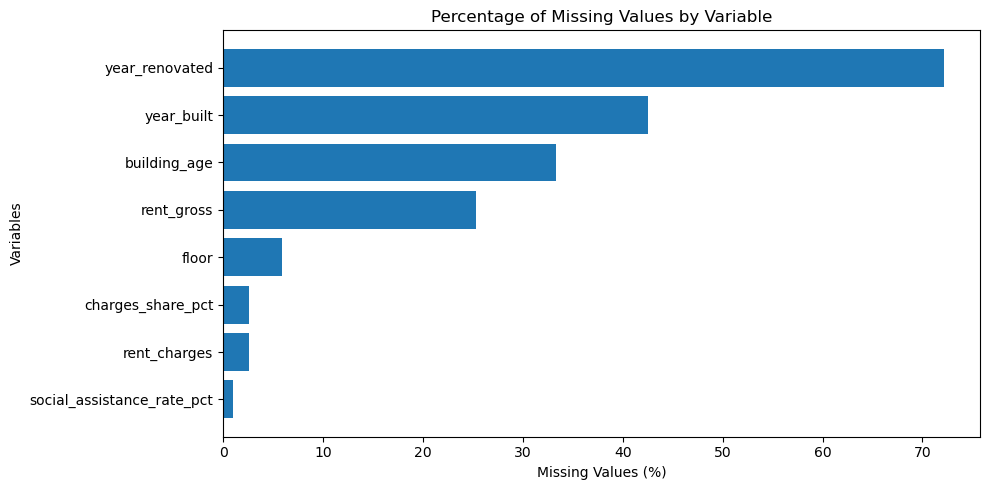

In [7]:

# Sort variables by their percentage of missing values.
missing_plot = missing_summary.sort_values(
    by="Missing (%)",
    ascending=True
)

# Create a figure with sufficient space for variable names.
plt.figure(figsize=(10, 5))

# Create a horizontal bar chart.
plt.barh(
    missing_plot.index,
    missing_plot["Missing (%)"]
)

# Add a descriptive chart title.
plt.title("Percentage of Missing Values by Variable")

# Label the horizontal axis.
plt.xlabel("Missing Values (%)")

# Label the vertical axis.
plt.ylabel("Variables")

# Adjust the layout to prevent overlapping labels.
plt.tight_layout()

# Display the chart.
plt.show()



#### Visualization of Missing Values

**Figure EDA-1: Percentage of Missing Values by Variable**

The horizontal bar chart illustrates the percentage of missing observations for each variable containing incomplete data in the cleaned rental dataset (n = 510).

**Key Observations:**

- Renovation year has the highest proportion of missing values (72.16%).
- Construction year (42.55%) and building age (33.33%) also show substantial missingness.
- Gross rent is missing in 25.29% of observations, while net rent is complete.
- Floor information and service charge variables have comparatively low missingness.
- The social assistance rate is the only incomplete socioeconomic indicator, with 0.98% missing values.

**Interpretation:**

Missing data is concentrated primarily in building-related characteristics rather than in the core rental price variables.

This suggests that the dataset is suitable for analyzing rental price distributions and relationships with key housing characteristics such as living area and number of rooms.

However, analyses involving construction year, renovation year, or building age require additional caution because missing observations could introduce selection bias.

The visualization identifies the extent of missingness but does not establish whether missing values occur randomly or systematically.

**Source:** Own visualization based on the cleaned Flatfox rental dataset.


In [8]:

# Group rental listings by canton.
missing_by_canton = df.groupby("kanton_geo").agg(
    total_listings=("year_built", "size"),
    missing_year_built=("year_built", lambda x: x.isna().sum())
)

# Calculate the percentage of missing construction years.
missing_by_canton["missing_pct"] = (
    missing_by_canton["missing_year_built"]
    / missing_by_canton["total_listings"]
    * 100
)

# Sort cantons by the highest percentage of missing values.
missing_by_canton = missing_by_canton.sort_values(
    by="missing_pct",
    ascending=False
)

# Display the results rounded to two decimal places.
display(missing_by_canton.round(2))


,total_listings,missing_year_built,missing_pct
kanton_geo,,,
UR,8,5,62.50
NW,10,5,50.00
ZG,43,21,48.84
LU,363,155,42.70
OW,10,4,40.00
SZ,76,27,35.53



### 2.6 Missing Construction Years by Canton

#### Methodology

To investigate potential geographical differences in data completeness, the proportion of missing construction years was calculated separately for each canton.

The dataset was grouped by canton using `groupby()`. For each canton, the total number of rental listings and the number of missing construction years were calculated.

The percentage of missing values was then determined relative to the total number of listings in each canton.

#### Results

| Canton | Total Listings | Missing Construction Years | Missing (%) |
|---|---:|---:|---:|
| Uri (UR) | 8 | 5 | 62.50% |
| Nidwalden (NW) | 10 | 5 | 50.00% |
| Zug (ZG) | 43 | 21 | 48.84% |
| Lucerne (LU) | 363 | 155 | 42.70% |
| Obwalden (OW) | 10 | 4 | 40.00% |
| Schwyz (SZ) | 76 | 27 | 35.53% |
| **Total** | **510** | **217** | **42.55%** |

#### Key Findings

- Uri has the highest percentage of missing construction years (62.50%), but only eight listings are available.
- Nidwalden and Zug also show relatively high proportions of missing construction years.
- Lucerne accounts for the largest absolute number of missing values (155), reflecting its dominant share of the dataset.
- Schwyz has the lowest percentage of missing construction years (35.53%).
- Missing construction years occur in all six cantons.

#### Interpretation and Limitations

The results indicate differences in the proportion of missing construction years across cantons.

However, the sample sizes vary substantially. In particular, Uri, Nidwalden, and Obwalden contain very few observations, making their percentages sensitive to individual listings.

The descriptive results do not establish whether missing construction years are statistically associated with canton or whether the differences arise from the composition of the sample.

Further analysis would be necessary to determine whether missingness is systematically related to geographical location or apartment characteristics.

Consequently, analyses involving construction year or building age should consider potential regional differences in data completeness.

No additional observations were excluded during this analysis.


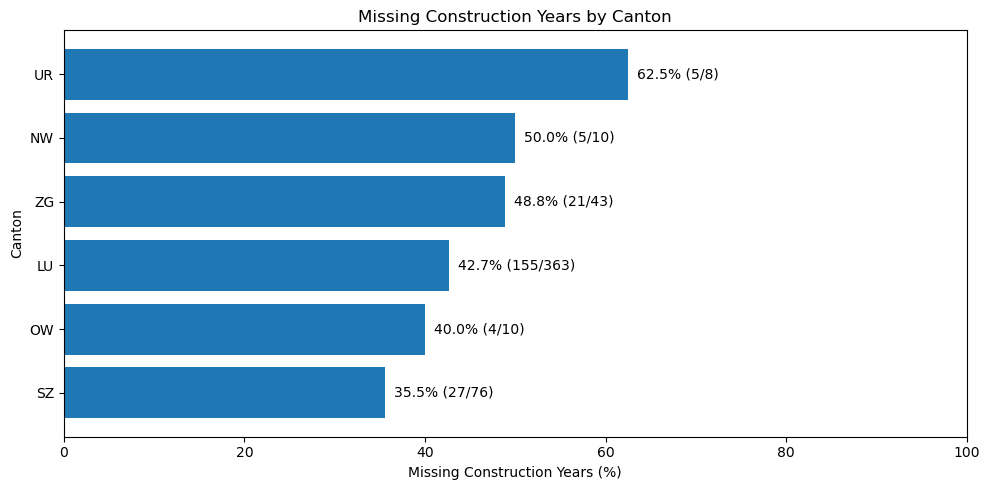

In [9]:

# Sort cantons by their percentage of missing construction years.
plot_data = missing_by_canton.sort_values(
    by="missing_pct",
    ascending=True
)

# Create a horizontal bar chart.
fig, ax = plt.subplots(figsize=(10, 5))

# Plot the percentage of missing construction years by canton.
bars = ax.barh(
    plot_data.index,
    plot_data["missing_pct"]
)

# Add the number of missing values and the total sample size.
for bar, (_, row) in zip(bars, plot_data.iterrows()):

    # Format the percentage and the number of observations.
    label = (
        f"{row['missing_pct']:.1f}% "
        f"({int(row['missing_year_built'])}/{int(row['total_listings'])})"
    )

    # Position the label next to the corresponding bar.
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        label,
        va="center"
    )

# Add a descriptive title and axis labels.
ax.set_title("Missing Construction Years by Canton")
ax.set_xlabel("Missing Construction Years (%)")
ax.set_ylabel("Canton")

# Extend the horizontal axis to make room for the labels.
ax.set_xlim(0, 100)

# Adjust the layout.
plt.tight_layout()

# Display the visualization.
plt.show()



#### Visualization of Missing Construction Years by Canton

**Figure EDA-2: Missing Construction Years by Canton**

The horizontal bar chart illustrates the percentage of missing construction years across the six cantons of Central Switzerland.

Each bar represents the proportion of rental listings without a reported construction year. The labels additionally indicate the number of missing values relative to the total number of observations in each canton.

**Key Observations:**

- Uri has the highest proportion of missing construction years (62.5%, 5 out of 8 listings).
- Nidwalden follows with 50.0% (5 out of 10 listings).
- Zug has a missing rate of 48.8% (21 out of 43 listings).
- Lucerne has a missing rate of 42.7% and the highest absolute number of missing observations (155 out of 363 listings).
- Obwalden has a missing rate of 40.0% (4 out of 10 listings).
- Schwyz has the lowest missing rate at 35.5% (27 out of 76 listings).

**Interpretation:**

The visualization indicates regional variation in the completeness of construction year information.

However, the number of available listings differs substantially between cantons. In particular, the small samples in Uri, Nidwalden, and Obwalden make the observed percentages sensitive to individual observations.

Therefore, the differences should be interpreted descriptively and should not be considered evidence of systematic geographical differences in missingness without further statistical investigation.

The results highlight a potential limitation for analyses involving building age and suggest that geographical differences in data completeness should be considered.

**Source:** Own visualization based on the cleaned Flatfox rental dataset (n = 510).



### 2.7 Data Quality Assessment – Summary

The exploratory data quality assessment was conducted on 510 rental listings containing 44 variables.

**Main Findings:**

- The primary analytical variables, including net rent, living area, and number of rooms, are complete.
- Eight variables contain missing observations.
- Missingness is concentrated in construction-related information.
- The proportion of missing construction years varies across cantons, although small regional sample sizes limit interpretation.
- The available socioeconomic indicators are largely complete.

**Conclusion:**

The cleaned dataset provides a suitable foundation for the planned exploratory analysis of rental prices and socioeconomic indicators.

However, incomplete building information and uneven geographical coverage must be considered when interpreting subsequent results.

No additional observations were excluded or imputed during this assessment.



## 3. Geographical Coverage

### 3.1 Distribution of Rental Listings by Canton

#### Objective

This analysis examines the geographical distribution of rental listings across the six cantons of Central Switzerland.

The objective is to identify differences in sample coverage, determine which regions are overrepresented or underrepresented in the collected listings, and evaluate potential implications for the representativeness of the dataset.

The analysis focuses on:

- Number of rental listings per canton
- Percentage of listings per canton
- Number of municipalities represented per canton
- Distribution of listings across municipalities


Geographical Coverage by Canton


,total_listings,municipalities,share_pct
kanton_geo,,,
LU,363,54,71.18
SZ,76,19,14.90
ZG,43,10,8.43
NW,10,5,1.96
OW,10,5,1.96
UR,8,5,1.57


Total rental listings: 510
Cantons represented: 6
Municipalities represented: 98
Municipalities with 1–2 listings: 47


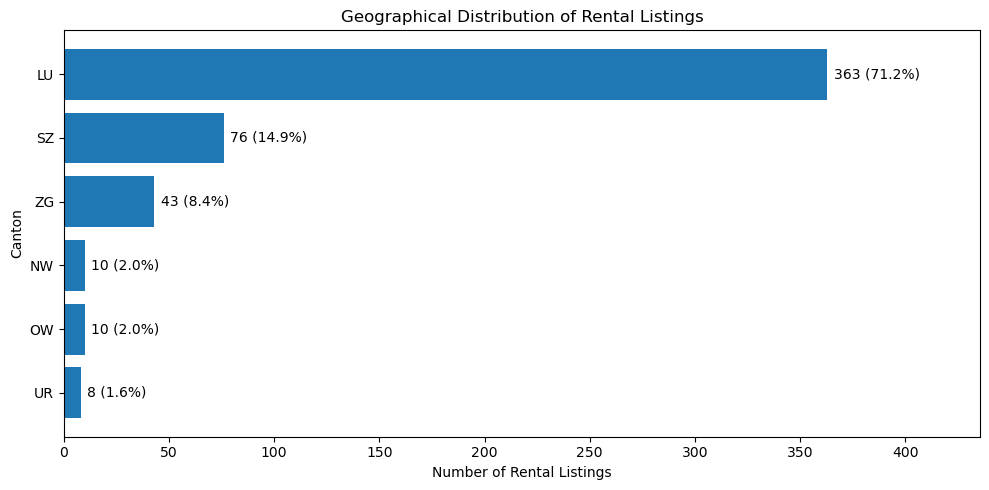

In [10]:

# ============================================================
# 3.1 Geographical Distribution of Rental Listings
# ============================================================

# Group rental listings by canton.
canton_summary = df.groupby("kanton_geo").agg(
    total_listings=("pk", "size"),
    municipalities=("gemeinde_bfs", "nunique")
)

# Calculate the percentage of listings per canton.
canton_summary["share_pct"] = (
    canton_summary["total_listings"] / len(df) * 100
)

# Sort cantons by the number of rental listings.
canton_summary = canton_summary.sort_values(
    by="total_listings",
    ascending=False
)

# Display the summary table.
print("Geographical Coverage by Canton")
display(canton_summary.round(2))

# Count the municipalities represented in the dataset.
total_municipalities = df["gemeinde_bfs"].nunique()

# Display the total geographical coverage.
print("Total rental listings:", len(df))
print("Cantons represented:", df["kanton_geo"].nunique())
print("Municipalities represented:", total_municipalities)

# Count the number of listings per municipality.
municipality_counts = df.groupby(
    ["kanton_geo", "gemeinde_bfs"]
).size()

# Identify municipalities with very few observations.
few_listings = (municipality_counts <= 2).sum()

# Display the number of municipalities with at most two listings.
print("Municipalities with 1–2 listings:", few_listings)

# ============================================================
# Visualization: Rental Listings by Canton
# ============================================================

# Create a horizontal bar chart.
fig, ax = plt.subplots(figsize=(10, 5))

# Plot the number of listings per canton.
bars = ax.barh(
    canton_summary.index,
    canton_summary["total_listings"]
)

# Label each bar with the number and percentage of listings.
for bar, (_, row) in zip(bars, canton_summary.iterrows()):

    # Format the label.
    label = (
        f"{int(row['total_listings'])} "
        f"({row['share_pct']:.1f}%)"
    )

    # Position the label to the right of the bar.
    ax.text(
        bar.get_width() + 3,
        bar.get_y() + bar.get_height() / 2,
        label,
        va="center"
    )

# Add the chart title and axis labels.
ax.set_title("Geographical Distribution of Rental Listings")
ax.set_xlabel("Number of Rental Listings")
ax.set_ylabel("Canton")

# Display the canton with the most listings at the top.
ax.invert_yaxis()

# Adjust axis limits and spacing.
ax.set_xlim(0, canton_summary["total_listings"].max() * 1.2)
plt.tight_layout()

# Save the figure to the project's figures folder.
fig.savefig("../figures/EDA_3_listings_by_canton.svg",
            bbox_inches="tight")

# Display the chart.
plt.show()



### 3.2 Geographical Distribution – Results and Interpretation

**Figure EDA-3: Geographical Distribution of Rental Listings**

#### Methodology

The geographical distribution of rental listings was examined using `groupby()` in pandas.

For each canton, the number and percentage of rental listings and the number of represented municipalities were calculated.

Additionally, the number of municipalities containing only one or two rental listings was determined to assess the limitations of municipality-level comparisons.

#### Results

| Canton | Rental Listings | Municipalities | Share (%) |
|---|---:|---:|---:|
| Lucerne (LU) | 363 | 54 | 71.18 |
| Schwyz (SZ) | 76 | 19 | 14.90 |
| Zug (ZG) | 43 | 10 | 8.43 |
| Nidwalden (NW) | 10 | 5 | 1.96 |
| Obwalden (OW) | 10 | 5 | 1.96 |
| Uri (UR) | 8 | 5 | 1.57 |
| **Total** | **510** | **98** | **100.00** |

Of the 98 municipalities represented in the dataset, 47 contain only one or two rental listings.

#### Key Findings

- Lucerne accounts for 71.18% of the rental listings, making it the dominant canton in the sample.
- Schwyz and Zug contribute 14.90% and 8.43%, respectively.
- Uri, Obwalden, and Nidwalden collectively account for only 28 listings.
- Almost half of the represented municipalities have no more than two observations.
- The distribution of rental listings is highly uneven across cantons and municipalities.

#### Interpretation and Limitations

The geographical distribution indicates a strong concentration of rental listings in Lucerne.

This imbalance may affect the interpretation of statistical results, particularly when individual rental listings are used as observations.

Municipalities with very few listings may have unstable estimates of median rental prices because individual observations can strongly influence the calculated values.

Furthermore, the geographical distribution of collected listings does not necessarily reflect the distribution of the entire rental housing market in Central Switzerland.

A comparison with the total number of municipalities and other relevant regional characteristics is therefore required to assess geographical coverage and potential sample selection bias.

These limitations are particularly relevant for Research Question 3, which investigates the stability of relationships between socioeconomic indicators and rental prices across urban and rural municipalities.

**Source:** Own analysis and visualization based on the cleaned Flatfox rental dataset (n = 510).


In [11]:

# ============================================================
# 3.3 Municipal Dataset – Initial Inspection
# ============================================================

# Define the path to the municipality indicator dataset.
municipality_path = Path(
    "../data/data_processed/gemeinde_indikatoren_zentralschweiz.csv"
)

# Load the municipality dataset.
df_municipalities = pd.read_csv(municipality_path)

# Display the dimensions of the dataset.
print("Number of municipalities:", len(df_municipalities))
print("Number of variables:", df_municipalities.shape[1])

# Display the available column names.
print("\nAvailable columns:")
print(df_municipalities.columns.tolist())

# Display the first five observations.
print("\nFirst five observations:")
display(df_municipalities.head())


Number of municipalities: 157
Number of variables: 44

Available columns:
['gemeinde_bfs', 'gemeinde_name', 'kanton_geo', 'income_median_chf', 'population_growth_pct', 'social_assistance_rate_pct', 'employment_per_100_residents', 'population_density_productive', 'household_size_mean', 'vacancy_rate_pct', 'population_age65plus_pct', 'new_dwellings_per_1000_residents', 'single_family_buildings_pct', 'foreign_population_pct', 'net_migration_per_1000_residents', 'gemeindeverzeichnis_stand', 'population_growth_from_year', 'population_growth_to_year', 'population_growth_gemeindestand', 'population_density_productive_gemeindestand', 'population_density_productive_year', 'household_size_mean_gemeindestand', 'household_size_mean_year', 'vacancy_rate_pct_gemeindestand', 'vacancy_rate_pct_year', 'population_age65plus_pct_gemeindestand', 'population_age65plus_pct_year', 'new_dwellings_per_1000_residents_gemeindestand', 'new_dwellings_per_1000_residents_year', 'single_family_buildings_pct_gemeindes

,gemeinde_bfs,gemeinde_name,kanton_geo,income_median_chf,population_growth_pct,social_assistance_rate_pct,employment_per_100_residents,population_density_productive,household_size_mean,vacancy_rate_pct,...,net_migration_per_1000_residents_year,social_assistance_estimated,social_assistance_rate_pct_year,social_assistance_rate_pct_gemeindestand,income_year,income_metric,employment_per_100_residents_year,employment_source_gemeindestand,employment_population_gemeindestand,employment_boundary_adjustment
0,1051,Adligenswil,LU,58000,1.548870,1.1,29.962613,830.3,2.37,0.64,...,2025,True,2024,01.01.2024,2022,median_steink,2024,01.01.2024,04.06.2025,No merger aggregation applied
1,1021,Aesch (LU),LU,55900,5.024088,1.0,40.536820,343.7,2.26,0.94,...,2025,False,2024,01.01.2024,2022,median_steink,2024,01.01.2024,04.06.2025,No merger aggregation applied
2,1121,Alberswil,LU,49950,0.816327,0.9,43.129252,212.3,2.25,0.58,...,2025,True,2024,01.01.2024,2022,median_steink,2024,01.01.2024,04.06.2025,No merger aggregation applied
3,1122,Altbüron,LU,48650,-0.098619,0.8,52.859961,150.3,2.36,0.84,...,2025,True,2024,01.01.2024,2022,median_steink,2024,01.01.2024,04.06.2025,No merger aggregation applied
4,1123,Altishofen,LU,51500,-0.826446,0.8,146.767137,143.1,2.54,0.24,...,2025,False,2024,01.01.2024,2022,median_steink,2024,01.01.2024,04.06.2025,No merger aggregation applied


Municipality Coverage by Canton


,total_municipalities,covered_municipalities,rental_listings,coverage_pct,not_covered
kanton_geo,,,,,
ZG,11,10,43,90.91,1
OW,7,5,10,71.43,2
LU,79,54,363,68.35,25
SZ,30,19,76,63.33,11
NW,11,5,10,45.45,6
UR,19,5,8,26.32,14



Total municipalities: 157
Municipalities with listings: 98
Municipalities without listings: 59


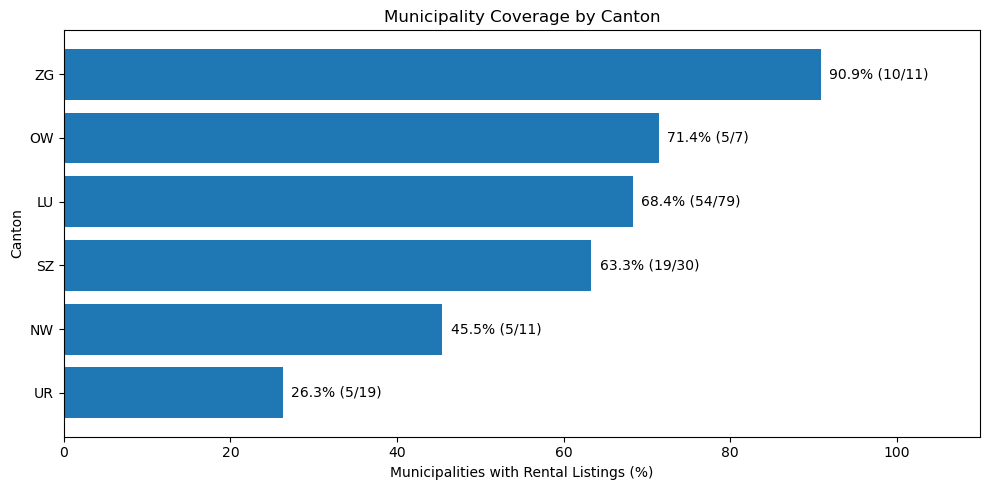

In [12]:

# ============================================================
# 3.4 Municipality Coverage Analysis
# ============================================================

# Count rental listings for each municipality.
listing_counts = df.groupby("gemeinde_bfs").size()

# Name the resulting variable.
listing_counts.name = "listing_count"

# Select the geographical information for all municipalities.
coverage = df_municipalities[
    ["gemeinde_bfs", "gemeinde_name", "kanton_geo"]
].copy()

# Verify that municipality identifiers are unique.
assert coverage["gemeinde_bfs"].is_unique

# Add the number of rental listings to each municipality.
coverage = coverage.join(
    listing_counts,
    on="gemeinde_bfs"
)

# Replace missing listing counts with zero.
coverage["listing_count"] = (
    coverage["listing_count"].fillna(0).astype(int)
)

# Identify municipalities with at least one rental listing.
coverage["has_listings"] = coverage["listing_count"] > 0

# Verify that all rental listings were matched.
assert coverage["listing_count"].sum() == len(df)

# Calculate municipality coverage by canton.
coverage_by_canton = coverage.groupby("kanton_geo").agg(
    total_municipalities=("gemeinde_bfs", "count"),
    covered_municipalities=("has_listings", "sum"),
    rental_listings=("listing_count", "sum")
)

# Calculate the percentage of municipalities covered.
coverage_by_canton["coverage_pct"] = (
    coverage_by_canton["covered_municipalities"]
    / coverage_by_canton["total_municipalities"]
    * 100
)

# Calculate the number of municipalities without listings.
coverage_by_canton["not_covered"] = (
    coverage_by_canton["total_municipalities"]
    - coverage_by_canton["covered_municipalities"]
)

# Sort cantons by coverage percentage.
coverage_by_canton = coverage_by_canton.sort_values(
    "coverage_pct",
    ascending=False
)

# Display the results.
print("Municipality Coverage by Canton")
display(coverage_by_canton.round(2))

# Display overall coverage statistics.
print("\nTotal municipalities:", len(coverage))
print("Municipalities with listings:", coverage["has_listings"].sum())
print("Municipalities without listings:", (~coverage["has_listings"]).sum())

# ============================================================
# Visualization
# ============================================================

# Sort values for the horizontal bar chart.
plot_coverage = coverage_by_canton.sort_values("coverage_pct")

# Create the figure.
fig, ax = plt.subplots(figsize=(10, 5))

# Plot coverage percentages.
bars = ax.barh(
    plot_coverage.index,
    plot_coverage["coverage_pct"]
)

# Add the municipality counts as labels.
for bar, (_, row) in zip(bars, plot_coverage.iterrows()):

    # Format percentage and covered municipality counts.
    label = (
        f"{row['coverage_pct']:.1f}% "
        f"({int(row['covered_municipalities'])}/"
        f"{int(row['total_municipalities'])})"
    )

    # Position the label next to each bar.
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        label,
        va="center"
    )

# Add title and labels.
ax.set_title("Municipality Coverage by Canton")
ax.set_xlabel("Municipalities with Rental Listings (%)")
ax.set_ylabel("Canton")

# Use the full percentage scale.
ax.set_xlim(0, 110)

# Optimize spacing.
plt.tight_layout()

# Save the visualization as an SVG file.
fig.savefig(
    "../figures/EDA_4_municipality_coverage.svg",
    bbox_inches="tight"
)

# Display the chart.
plt.show()



### 3.3 Municipality Coverage Analysis

**Figure EDA-4: Municipality Coverage by Canton**

#### Methodology

Municipality coverage was assessed by comparing the municipalities represented in the cleaned rental dataset with all municipalities included in the official municipal indicator dataset.

Rental listings were counted for each municipality using the BFS municipality identifier (`gemeinde_bfs`).

Municipalities with at least one rental listing were classified as covered, while municipalities without listings were classified as not covered.

Coverage percentages were calculated separately for each canton.

#### Results

| Canton | Total Municipalities | Covered | Not Covered | Coverage (%) |
|---|---:|---:|---:|---:|
| Zug (ZG) | 11 | 10 | 1 | 90.91 |
| Obwalden (OW) | 7 | 5 | 2 | 71.43 |
| Lucerne (LU) | 79 | 54 | 25 | 68.35 |
| Schwyz (SZ) | 30 | 19 | 11 | 63.33 |
| Nidwalden (NW) | 11 | 5 | 6 | 45.45 |
| Uri (UR) | 19 | 5 | 14 | 26.32 |
| **Total** | **157** | **98** | **59** | **62.42** |

#### Key Findings

- The rental dataset covers 98 of the 157 municipalities in Central Switzerland (62.42%).
- Consequently, 59 municipalities (37.58%) have no rental listings in the collected sample.
- Zug has the highest geographical coverage (90.91%).
- Uri has the lowest coverage (26.32%).
- Lucerne contributes the largest number of covered municipalities (54), but 25 municipalities remain unrepresented.
- Geographical coverage varies substantially between cantons.

#### Interpretation

The results reveal considerable differences in geographical coverage across Central Switzerland.

Although the dataset includes all six cantons, the proportion of represented municipalities differs substantially.

This distinction is important because the number of rental listings alone does not provide sufficient information about geographical representativeness.

Municipalities without listings cannot contribute directly to the municipality-level analysis of asking rents.

Additionally, municipalities with only a small number of listings may produce unstable estimates of local median rental prices.

These limitations may affect the interpretation of relationships between socioeconomic indicators and rental prices.

#### Implications for Research Question 3

Research Question 3 investigates the stability of socioeconomic relationships across urban and rural municipalities.

The observed differences in geographical coverage indicate that further analysis is necessary to determine whether urban and rural municipalities are equally represented.

If the missing municipalities differ systematically in their socioeconomic characteristics, the observed relationships may not generalize to all municipalities in Central Switzerland.

#### Limitations

The analysis measures whether a municipality is represented by at least one listing, not whether its rental housing market is adequately sampled.

The absence of listings does not imply that no rental properties exist in a municipality.

Furthermore, differences in coverage alone do not establish whether the observed sample is representative of the entire regional rental market.

Additional comparisons between covered and uncovered municipalities are required.

**Source:** Own analysis based on the cleaned Flatfox rental dataset (n = 510) and the official municipal indicator dataset (157 municipalities).


In [13]:

# ============================================================
# 3.5 Comparison of Covered and Uncovered Municipalities
# ============================================================

# Select the socioeconomic indicators for comparison.
indicators = [
    "income_median_chf",
    "population_density_productive",
    "vacancy_rate_pct",
    "social_assistance_rate_pct"
]

# Combine municipality coverage with socioeconomic indicators.
comparison = coverage[
    ["gemeinde_bfs", "has_listings"]
].merge(
    df_municipalities[["gemeinde_bfs"] + indicators],
    on="gemeinde_bfs",
    how="left",
    validate="one_to_one"
)

# Calculate the median of each indicator for both groups.
comparison_summary = comparison.groupby(
    "has_listings"
)[indicators].median().T

# Rename groups to improve readability.
comparison_summary = comparison_summary.rename(
    columns={
        False: "Without listings",
        True: "With listings"
    }
)

# Display the comparison.
print("Socioeconomic Comparison of Municipalities")
display(comparison_summary.round(2))

# Display the number of municipalities in each group.
print("\nNumber of municipalities:")
print(comparison["has_listings"].value_counts())

# Display missing values for the selected indicators.
print("\nMissing socioeconomic values:")
display(comparison[indicators].isna().sum())


Socioeconomic Comparison of Municipalities


has_listings,Without listings,With listings
income_median_chf,49000.00,52675.00
population_density_productive,122.40,330.40
vacancy_rate_pct,0.54,0.52
social_assistance_rate_pct,0.80,1.20



Number of municipalities:
has_listings
True     98
False    59
Name: count, dtype: int64

Missing socioeconomic values:


income_median_chf                 0
population_density_productive     0
vacancy_rate_pct                  0
social_assistance_rate_pct       18
dtype: int64


### 3.4 Comparison of Covered and Uncovered Municipalities

#### Methodology

To assess potential sample selection bias, municipalities with at least one rental listing were compared with municipalities without listings.

Four socioeconomic indicators were examined: median taxable income, population density, vacancy rate, and social assistance rate.

Group medians were calculated to compare the socioeconomic characteristics of the 98 covered and 59 uncovered municipalities.

#### Results

| Indicator | Without Listings | With Listings |
|---|---:|---:|
| Median taxable income (CHF) | 49,000 | 52,675 |
| Population density | 122.40 | 330.40 |
| Vacancy rate (%) | 0.54 | 0.52 |
| Social assistance rate (%) | 0.80 | 1.20 |

#### Key Findings and Interpretation

Municipalities represented in the rental dataset have a higher median taxable income and substantially higher population density than municipalities without listings.

Vacancy rates are similar across both groups, while social assistance rates are higher among represented municipalities.

However, social assistance data is missing for 18 municipalities, which limits the completeness of this comparison.

The findings suggest that the geographical coverage of the rental sample is not uniform across different socioeconomic environments.

In particular, municipalities with higher population densities are more frequently represented in the dataset.

This may introduce sample selection bias and limit the generalizability of the analysis to all municipalities in Central Switzerland.

The comparison is descriptive and does not establish the causes of differences in listing coverage.

### 3.5 Geographical Coverage – Summary

The dataset contains 510 rental listings across 98 of the 157 municipalities in Central Switzerland.

Coverage varies substantially between cantons, and many municipalities have only a small number of observations.

Furthermore, municipalities with and without listings differ in socioeconomic characteristics, especially income and population density.

These findings highlight limitations in geographical representativeness that should be considered when interpreting the project's statistical results, particularly the urban–rural comparisons.

No additional observations were excluded during this analysis.


Descriptive Statistics


,rent_net,rent_net_per_m2,surface_living,number_of_rooms
count,510.00,510.00,510.00,510.00
mean,2192.56,25.21,91.14,3.52
std,979.68,7.66,42.48,1.10
min,517.00,11.00,23.00,1.00
25%,1572.50,19.68,67.00,2.50
50%,1970.00,23.62,85.00,3.50
75%,2457.50,29.15,106.00,4.50
max,9000.00,51.82,440.00,8.00



Spearman Correlations


,surface_living,number_of_rooms,rent_net_per_m2
surface_living,1.000,0.842,-0.411
number_of_rooms,0.842,1.000,-0.333
rent_net_per_m2,-0.411,-0.333,1.000


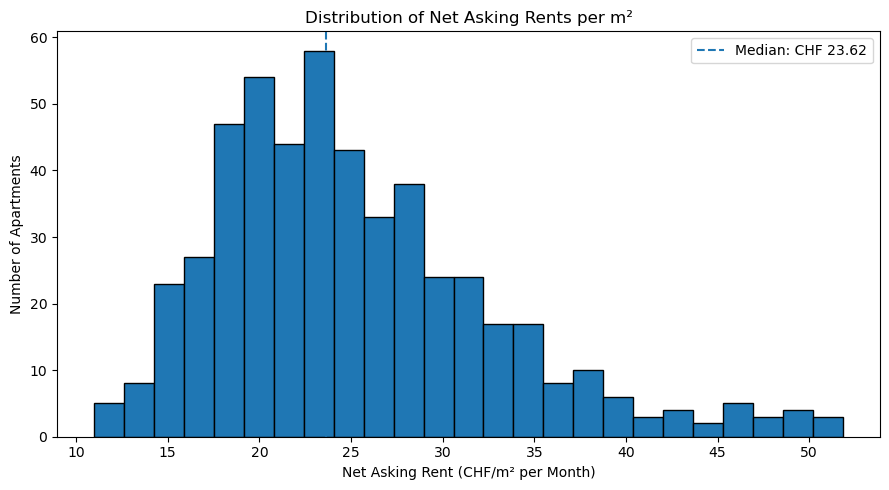

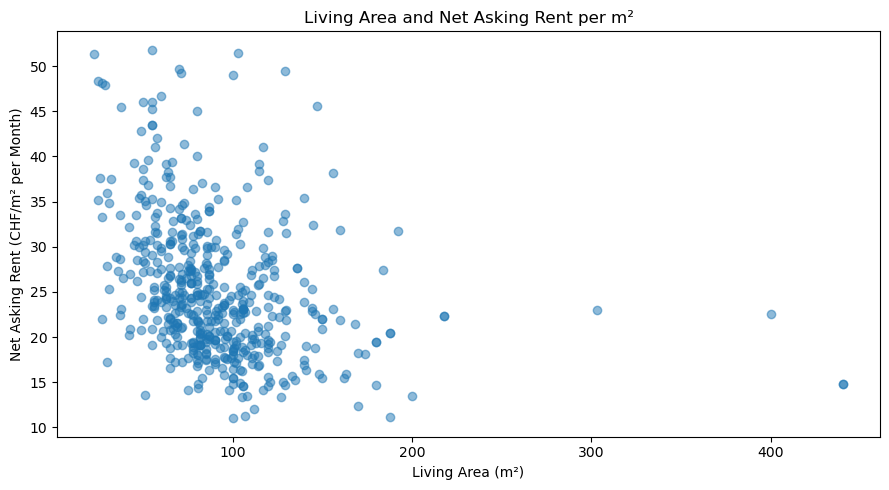

In [14]:

# ============================================================
# 4–5. Rental Prices and Housing Characteristics
# ============================================================

# Select the main rental price and housing variables.
variables = [
    "rent_net",
    "rent_net_per_m2",
    "surface_living",
    "number_of_rooms"
]

# Calculate descriptive statistics.
summary = df[variables].describe()

# Display descriptive statistics.
print("Descriptive Statistics")
display(summary.round(2))

# Calculate Spearman correlations between housing
# characteristics and net rent per square meter.
correlations = df[
    ["surface_living", "number_of_rooms", "rent_net_per_m2"]
].corr(method="spearman")

# Display the correlation matrix.
print("\nSpearman Correlations")
display(correlations.round(3))

# ============================================================
# Figure EDA-5: Distribution of Net Asking Rents per m²
# ============================================================

# Calculate the median rent per square meter.
median_rent = df["rent_net_per_m2"].median()

# Create a histogram.
fig, ax = plt.subplots(figsize=(9, 5))

# Plot the distribution of net rent per square meter.
ax.hist(
    df["rent_net_per_m2"].dropna(),
    bins=25,
    edgecolor="black"
)

# Mark the sample median.
ax.axvline(
    median_rent,
    linestyle="--",
    label=f"Median: CHF {median_rent:.2f}"
)

# Add labels and legend.
ax.set_title("Distribution of Net Asking Rents per m²")
ax.set_xlabel("Net Asking Rent (CHF/m² per Month)")
ax.set_ylabel("Number of Apartments")
ax.legend()

# Optimize and save the figure.
plt.tight_layout()
fig.savefig(
    "../figures/EDA_5_rent_distribution.svg",
    bbox_inches="tight"
)

# Display the chart.
plt.show()

# ============================================================
# Figure EDA-6: Living Area vs. Net Rent per m²
# ============================================================

# Create a scatter plot.
fig, ax = plt.subplots(figsize=(9, 5))

# Plot each apartment according to size and price per m².
ax.scatter(
    df["surface_living"],
    df["rent_net_per_m2"],
    alpha=0.5
)

# Add descriptive labels.
ax.set_title("Living Area and Net Asking Rent per m²")
ax.set_xlabel("Living Area (m²)")
ax.set_ylabel("Net Asking Rent (CHF/m² per Month)")

# Optimize and save the figure.
plt.tight_layout()
fig.savefig(
    "../figures/EDA_6_living_area_vs_rent.svg",
    bbox_inches="tight"
)

# Display the chart.
plt.show()



## 4. Rental Price Distributions

### 4.1 Descriptive Statistics

The analysis examines 510 rental apartment listings in Central Switzerland.

The median monthly net asking rent is CHF 1,970, while the mean is CHF 2,192.56.

The median net asking rent per square meter is CHF 23.62, compared with a mean of CHF 25.21.

The interquartile range of net asking rents per square meter extends from CHF 19.68 to CHF 29.15.

### 4.2 Distribution of Net Asking Rents

**Figure EDA-5: Distribution of Net Asking Rents per m²**

The histogram illustrates the distribution of monthly net asking rents per square meter.

The distribution is positively skewed, with most observations concentrated in the lower and middle price ranges and a smaller number of apartments exhibiting substantially higher rents.

The mean exceeding the median is consistent with this right-skewed distribution.

The observed net asking rents range from CHF 11.00 to CHF 51.82 per square meter.

### 4.3 Interpretation

The results indicate considerable variation in net asking rents within the collected sample.

Median values provide a useful measure of central tendency because they are less sensitive to unusually expensive apartments than arithmetic means.

The distribution reflects the collected Flatfox listings and should not be interpreted as representative of the entire rental market in Central Switzerland.

---

## 5. Housing Characteristics

### 5.1 Descriptive Overview

The median living area is 85 m², while the mean is 91.14 m².

The median apartment contains 3.5 rooms.

Living areas range from 23 m² to 440 m², indicating substantial variation in apartment size.

### 5.2 Living Area and Rental Prices

**Figure EDA-6: Living Area and Net Asking Rent per m²**

A scatter plot was used to examine the relationship between living area and net asking rent per square meter.

Spearman rank correlations were calculated to assess monotonic associations.

The results show:

- Living area and net rent per m²: ρ = -0.411
- Number of rooms and net rent per m²: ρ = -0.333
- Living area and number of rooms: ρ = 0.842

### 5.3 Interpretation

The analysis indicates a moderate negative association between living area and net asking rent per square meter.

Apartments with larger living areas tend to have lower rental prices per square meter in the observed sample.

However, this relationship requires careful interpretation because living area is also used to calculate rent per square meter.

Living area and the number of rooms are strongly positively correlated, indicating that both variables capture related aspects of apartment size.

The scatter plot also shows considerable variation in rental prices among apartments of similar size.

This suggests that additional property characteristics and location-related factors may be relevant for explaining rental price differences.

These descriptive relationships do not establish causal effects.

**Source:** Own calculations and visualizations based on the cleaned Flatfox rental dataset (n = 510).


In [15]:

# ============================================================
# 6. Socioeconomic Indicators – Exploratory Comparison
# ============================================================

# Select additional socioeconomic variables.
indicators = [
    "population_growth_pct",
    "population_age65plus_pct",
    "foreign_population_pct",
    "employment_per_100_residents"
]

# Combine municipal coverage with the socioeconomic data.
socioeconomic_eda = coverage[
    ["gemeinde_bfs", "has_listings"]
].merge(
    df_municipalities[["gemeinde_bfs"] + indicators],
    on="gemeinde_bfs",
    how="left",
    validate="one_to_one"
)

# Calculate group medians for municipalities with and without listings.
group_medians = socioeconomic_eda.groupby(
    "has_listings"
)[indicators].median().T

# Rename the comparison groups.
group_medians = group_medians.rename(
    columns={
        False: "Without listings",
        True: "With listings"
    }
)

# Display the socioeconomic comparison.
print("Socioeconomic Indicators by Municipality Coverage")
display(group_medians.round(2))

# Calculate descriptive statistics across all 157 municipalities.
print("\nSocioeconomic Indicators – Overall Distribution")

# Display the number of available values, median and quartiles.
overall_summary = socioeconomic_eda[indicators].describe().loc[
    ["count", "25%", "50%", "75%"]
]

display(overall_summary.T.round(2))

# Display missing observations for each indicator.
print("\nMissing Values")
display(socioeconomic_eda[indicators].isna().sum())


Socioeconomic Indicators by Municipality Coverage


has_listings,Without listings,With listings
population_growth_pct,0.33,0.61
population_age65plus_pct,20.40,19.75
foreign_population_pct,13.50,19.55
employment_per_100_residents,38.57,46.45



Socioeconomic Indicators – Overall Distribution


,count,25%,50%,75%
population_growth_pct,157.0,-0.16,0.60,1.52
population_age65plus_pct,157.0,17.60,19.80,22.20
foreign_population_pct,157.0,11.40,17.40,25.00
employment_per_100_residents,157.0,32.70,43.23,57.17



Missing Values


population_growth_pct           0
population_age65plus_pct        0
foreign_population_pct          0
employment_per_100_residents    0
dtype: int64


## 6. Exploratory Analysis of Socioeconomic Indicators

### 6.1 Methodology

Four additional socioeconomic indicators were examined to assess differences between municipalities with and without rental listings.

The analysis includes population growth, the proportion of residents aged 65 and over, the share of foreign residents, and employment per 100 residents.

Group medians were calculated for 98 municipalities with listings and 59 municipalities without listings.

Descriptive statistics were also calculated for all 157 municipalities.

### 6.2 Results

| Indicator | Without Listings | With Listings |
|---|---:|---:|
| Population growth (%) | 0.33 | 0.61 |
| Population aged 65+ (%) | 20.40 | 19.75 |
| Foreign population (%) | 13.50 | 19.55 |
| Employment per 100 residents | 38.57 | 46.45 |

All four indicators are available for all 157 municipalities, with no missing observations.

### 6.3 Interpretation

Municipalities represented in the rental dataset show higher median population growth, a higher proportion of foreign residents, and more employment per 100 residents.

The median share of residents aged 65 and over is slightly lower in municipalities with rental listings.

These findings suggest that the geographical coverage of rental listings differs across socioeconomic environments.

However, the analysis is descriptive and does not establish whether these differences are statistically significant or causally related to listing availability.

---

## 7. Sample Representativeness

### 7.1 Assessment

The analysis of sample representativeness combines the geographical coverage results from Chapter 3 with the socioeconomic comparisons conducted in Chapters 3 and 6.

The rental dataset includes 510 apartments from 98 of the 157 municipalities in Central Switzerland.

Municipalities with listings exhibit higher median income, population density, population growth, foreign population share, and employment per 100 residents than municipalities without listings.

Furthermore, the rental sample is strongly concentrated in Lucerne, and many represented municipalities contain only one or two observations.

### 7.2 Implications

The findings indicate potential selection bias in the geographical composition of the rental sample.

Municipalities with certain socioeconomic characteristics are more frequently represented, which may influence the observed relationships between socioeconomic indicators and rental prices.

This is particularly relevant for Research Question 3, which compares associations across urban and rural municipalities.

The results should therefore not be generalized to all rental apartments or municipalities in Central Switzerland without considering these limitations.

### 7.3 Limitations

Municipality coverage does not measure how well the available listings represent the local rental housing market.

The analysis is based on one platform and a limited collection period.

Differences between covered and uncovered municipalities were evaluated descriptively using group medians, without statistical significance testing.

Consequently, the findings identify potential representativeness concerns rather than demonstrating the magnitude of selection bias.

No additional observations were excluded during this analysis.

**Source:** Own exploratory analysis based on 510 Flatfox rental listings and socioeconomic indicators for 157 municipalities in Central Switzerland.



## 8. Overall Findings and Limitations

### 8.1 Summary of Key Findings

The exploratory data analysis examined 510 rental apartment listings from 98 municipalities across six cantons in Central Switzerland.

The analysis focused on data quality, geographical coverage, rental price distributions, housing characteristics, and socioeconomic differences between represented and non-represented municipalities.

**Data Quality**

- The dataset contains 44 variables, of which 8 have missing values.
- Core variables, including net rent, living area, and number of rooms, are complete.
- Missing values are concentrated in construction-related information, particularly renovation year (72.16%) and construction year (42.55%).
- No additional observations were excluded or imputed during the EDA.

**Geographical Coverage**

- Rental listings are available for 98 of the 157 municipalities (62.42%).
- Lucerne accounts for 71.18% of all rental listings.
- A total of 47 represented municipalities contain only one or two listings.
- Geographical coverage differs considerably between cantons.

**Rental Price Distribution**

- The median monthly net asking rent is CHF 1,970.
- The median net asking rent per square meter is CHF 23.62.
- Rental prices per square meter show a right-skewed distribution.
- The observed variation indicates substantial differences between apartments.

**Housing Characteristics**

- The median living area is 85 m².
- The median number of rooms is 3.5.
- Living area and net rent per square meter show a negative Spearman correlation (ρ = -0.411).
- Living area and number of rooms are strongly correlated (ρ = 0.842).

**Socioeconomic Characteristics**

Municipalities with rental listings have higher median income, population density, population growth, foreign population share, and employment per 100 residents than municipalities without listings.

These descriptive differences suggest that the rental sample covers socioeconomic environments unevenly.

### 8.2 Main Limitations

**Geographical Representation**

The rental sample covers only 62.42% of Central Switzerland's municipalities and is strongly concentrated in Lucerne.

**Small Local Samples**

Many municipalities contain only one or two listings, limiting the reliability of municipality-level rental price estimates.

**Platform and Time Coverage**

The dataset is based on Flatfox listings collected during a limited period and does not necessarily represent the entire rental housing market.

**Incomplete Building Information**

Missing construction and renovation information limits analyses involving building age and related characteristics.

**Potential Selection Bias**

Municipalities with and without listings differ in several socioeconomic characteristics. These differences may influence the interpretation and generalizability of statistical relationships.

**Observational Data**

The EDA identifies descriptive patterns and statistical associations but does not establish causal relationships.

### 8.3 Contribution to the Research Questions

The EDA provides important contextual information for interpreting the project's three research questions.

For RQ1 and RQ2, the analysis highlights differences in rental price distributions, apartment characteristics, and geographical representation that should be considered when evaluating socioeconomic associations.

For RQ3, the uneven geographical coverage and small numbers of observations in many municipalities are particularly relevant when comparing urban and rural areas.

The EDA therefore complements the existing correlation and regression analyses by identifying data quality and sample composition limitations.

### 8.4 Final Conclusion

The exploratory data analysis demonstrates that the cleaned rental dataset provides a usable basis for examining net asking rents and their associations with housing and socioeconomic characteristics.

However, the strong concentration of listings in selected regions, the limited number of observations in many municipalities, and differences between represented and non-represented municipalities restrict the generalizability of the findings.

These limitations should be explicitly considered when interpreting the statistical results and drawing conclusions about rental prices in Central Switzerland.
